# 5. Consumption by operating period, base flow and off-hours use

The day is split into operating periods (see `src/eda_utils.py`):

| period | hours | CAF_CENTRAL |
|---|---|---|
| night | 00:00–05:00 | night |
| morning_prep | 05:00–07:00 | morning_prep |
| morning_service | 07:00–13:30 | morning_service |
| afternoon_prep | 13:30–16:00 | closed |
| evening_service | 16:00–19:30 | closed |
| closed | 19:30–24:00 | closed |

The analysis uses valid 15-min intervals of **weekdays during classes, holidays excluded**.
Because few days are complete (especially for `CAF_C1`), a typical day is built from the mean
flow of each 15-min slot of the day (96 slots), and the volume of each period is the sum of
its slots. This uses every valid interval instead of only complete days.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import eda_utils as u

u.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

df = u.build_dataset()
valid = df.dropna(subset=["consumption_L"])
op = valid[valid["is_weekday"] & ~valid["is_holiday"] & (valid["academic_period"] == "classes")]

slot = op.index.hour * 4 + op.index.minute // 15
typical = op.groupby(["cafeteria", slot])["flow_Ls"].agg(["mean", "count"])
typical.index.names = ["cafeteria", "slot"]
typical = typical.reset_index()
slot_time = pd.Timestamp("2000-01-03") + pd.to_timedelta(typical["slot"] * 15, unit="min")
typical["operating_period"] = np.concatenate([
    u.operating_period(pd.DatetimeIndex(slot_time[typical["cafeteria"] == caf]), caf)
    for caf in typical["cafeteria"].unique()
])
typical["volume_L"] = typical["mean"] * u.BIN_SECONDS
typical.groupby("cafeteria")["count"].agg(["min", "median"]).rename(
    columns={"min": "fewest intervals per slot", "median": "median intervals per slot"})

,fewest intervals per slot,median intervals per slot
cafeteria,,
CAF_C1,22,30.000
CAF_C3,301,315.000
CAF_CENTRAL,346,351.000


## 5.1 Typical weekday volume and its share per operating period

typical weekday volume (L) share (%)                               \
                                 total     night morning_prep morning_service   
cafeteria                                                                       
CAF_C1                       4,376.900     0.100       10.900          53.900   
CAF_C3                       1,690.700     3.700       15.200          52.500   
CAF_CENTRAL                    991.200     0.400       22.500          70.700   

                                                   
            afternoon_prep evening_service closed  
cafeteria                                          
CAF_C1              16.900          16.100  2.100  
CAF_C3               9.500          16.700  2.400  
CAF_CENTRAL          0.000           0.000  6.400

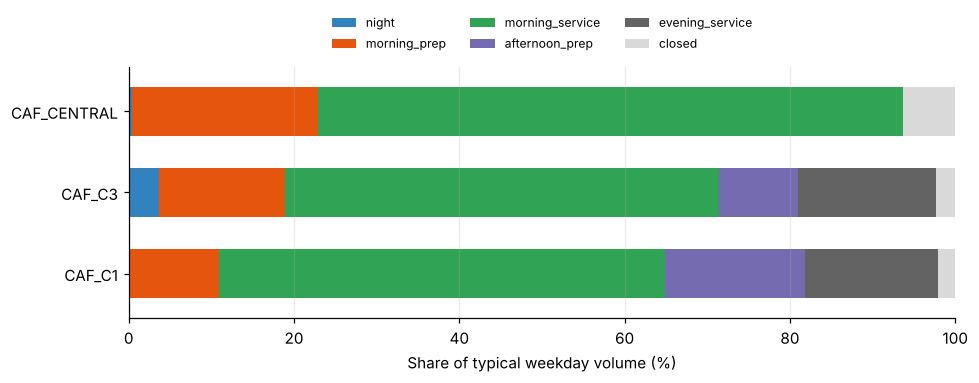

In [2]:
by_period = (typical.groupby(["cafeteria", "operating_period"])["volume_L"].sum()
                    .unstack().reindex(columns=u.OPERATING_ORDER).fillna(0))
share = by_period.div(by_period.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
share.plot(kind="barh", stacked=True, ax=ax, colormap="tab20c", width=0.6)
ax.set_xlabel("Share of typical weekday volume (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(ncol=3, bbox_to_anchor=(0.5, 1.02), loc="lower center", fontsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
u.savefig(fig, "05_share_by_period")
pd.concat({"typical weekday volume (L)": by_period.sum(axis=1).to_frame("total"),
           "share (%)": share}, axis=1).round(1)

## 5.2 Mean flow per operating period (L/s)

In [3]:
op.groupby(["cafeteria", "operating_period"])["flow_Ls"].mean().unstack().reindex(columns=u.OPERATING_ORDER)

operating_period,night,morning_prep,morning_service,afternoon_prep,evening_service,closed
cafeteria,,,,,,
CAF_C1,0.000,0.067,0.100,0.084,0.058,0.005
CAF_C3,0.003,0.036,0.038,0.018,0.022,0.002
CAF_CENTRAL,0.000,0.031,0.030,NaN,NaN,0.002


## 5.3 Base (night) flow

Flow between 00:00 and 05:00, when the cafeterias are closed. A base flow above zero can
indicate leaks or equipment that keeps running at night. "Nights with zero flow" counts only
nights whose 20 intervals are all valid.

In [4]:
night = op[op["operating_period"] == "night"]
per_night = night.groupby(["cafeteria", "date"])["consumption_L"].agg(["sum", "count"])
full_nights = per_night[per_night["count"] == 20]
base = pd.DataFrame({
    "night flow (L/s)": night.groupby("cafeteria")["flow_Ls"].mean(),
    "night volume (L)": by_period["night"],
    "share of typical day (%)": share["night"],
    "complete nights": full_nights.groupby(level=0).size(),
    "nights with zero flow (%)": (full_nights["sum"] == 0).groupby(level=0).mean() * 100,
})
base

,night flow (L/s),night volume (L),share of typical day (%),complete nights,nights with zero flow (%)
cafeteria,,,,,
CAF_C1,0.000,2.374,0.054,16,75.000
CAF_C3,0.003,62.298,3.685,301,6.312
CAF_CENTRAL,0.000,4.187,0.422,340,56.765


## 5.4 Productive and non-productive consumption

Productive = preparation and service periods; non-productive = night and closed periods.

,productive,non-productive
cafeteria,,
CAF_C1,97.900,2.100
CAF_C3,93.900,6.100
CAF_CENTRAL,93.200,6.800


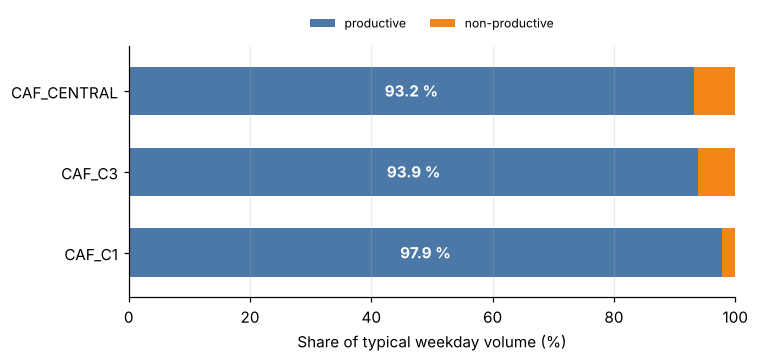

In [5]:
productive = ["morning_prep", "morning_service", "afternoon_prep", "evening_service"]
prod_pct = pd.DataFrame({
    "productive": share[productive].sum(axis=1),
    "non-productive": share[["night", "closed"]].sum(axis=1),
})
fig, ax = plt.subplots(figsize=(7, 3.4))
prod_pct.plot(kind="barh", stacked=True, ax=ax, color=["#4C78A8", "#F58518"], width=0.6)
for i, v in enumerate(prod_pct["productive"]):
    ax.text(v / 2, i, f"{v:.1f} %", ha="center", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 100)
ax.legend(ncol=2, bbox_to_anchor=(0.5, 1.02), loc="lower center", fontsize=8)
ax.set_xlabel("Share of typical weekday volume (%)")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
fig.tight_layout()
u.savefig(fig, "05_productive_share")
prod_pct.round(1)

## 5.5 Off-hours consumption events

An interval is flagged when the cafeteria should be idle (night or closed periods, weekends
or holidays, during classes) and its flow is more than 2.5 times the cafeteria's mean night
flow. Where the night flow is practically zero (`CAF_C1`, `CAF_CENTRAL`), any off-hours use is
flagged; the threshold is a screening rule, not a leak diagnosis.

In [6]:
v = valid[valid["academic_period"] == "classes"]
base_flow = night.groupby("cafeteria")["flow_Ls"].mean()
idle = v["operating_period"].isin(["night", "closed"]) | ~v["is_weekday"] | v["is_holiday"]
flag = idle & (v["flow_Ls"] > 2.5 * v["cafeteria"].map(base_flow))
events = v[flag].copy()
events["type"] = np.where(events["is_holiday"], "holiday",
                          np.where(~events["is_weekday"], "weekend", "weekday off-hours"))
summary = pd.DataFrame({
    "threshold (L/s)": 2.5 * base_flow,
    "flagged intervals": events.groupby("cafeteria").size(),
    "idle intervals": v[idle].groupby("cafeteria").size(),
})
summary["flagged (% of idle)"] = summary["flagged intervals"] / summary["idle intervals"] * 100
summary

,threshold (L/s),flagged intervals,idle intervals,flagged (% of idle)
cafeteria,,,,
CAF_C1,0.000,84,2770,3.032
CAF_C3,0.009,688,25555,2.692
CAF_CENTRAL,0.001,5164,36865,14.008


In [7]:
pd.crosstab(events["cafeteria"], events["type"])

type,holiday,weekday off-hours,weekend
cafeteria,,,
CAF_C1,0,83,1
CAF_C3,2,489,197
CAF_CENTRAL,4,4221,939


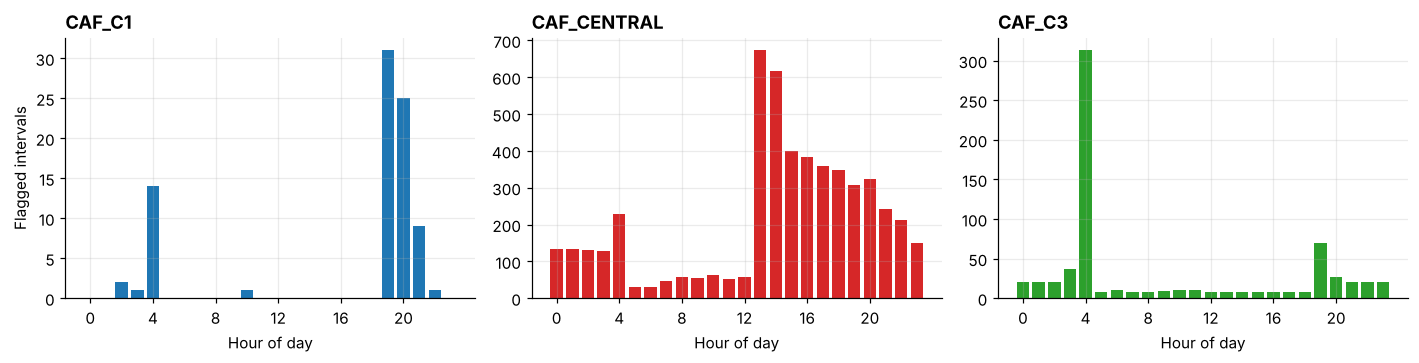

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=False)
for ax, caf in zip(axes, u.CAFETERIAS):
    e = events[events["cafeteria"] == caf]
    counts = e.groupby(e.index.hour).size().reindex(range(24), fill_value=0)
    ax.bar(counts.index, counts.values, color=u.COLORS[caf])
    ax.set_title(caf, loc="left")
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Flagged intervals")
fig.tight_layout()
u.savefig(fig, "05_offhours_by_hour")

## Observations

* **Where the water goes.** Morning service is the largest share in all three cafeterias
  (54 % in `CAF_C1`, 53 % in `CAF_C3` and 71 % in `CAF_CENTRAL`). Morning preparation adds
  11–23 %. A typical weekday during classes uses about 4.4 m³ in `CAF_C1` (indicative, built
  from ~30 intervals per slot), 1.7 m³ in `CAF_C3` and 1.0 m³ in `CAF_CENTRAL`.
* **Base flow.** `CAF_C3` has a persistent night flow of about 0.003 L/s (≈ 60 L per night,
  3.7 % of its typical day), and only 6 % of its complete nights have zero flow. This
  continuous use is worth checking on site (leak, cistern or equipment left running). In
  `CAF_C1` and `CAF_CENTRAL` most nights are at zero.
* **Non-productive use** (night and closed periods) is 2–7 % of the typical day. In
  `CAF_CENTRAL` it comes mainly from the hours right after closing (13:30–16:00), which is
  consistent with cleaning after service.
* **Off-hours flags.** `CAF_CENTRAL` has the most flagged intervals (14 % of its idle intervals),
  concentrated in the afternoon after closing. In `CAF_C3`, the flags cluster at 04:00, which
  suggests that preparation starts before the 05:00 boundary used here.